In [1]:
%load_ext autoreload
%autoreload 2

import sys
from pathlib import Path
import os

ROOT_DIR = Path.cwd().parent
if str(ROOT_DIR) not in sys.path:
    sys.path.append(str(ROOT_DIR))

from src import setup_workspace, query_to_df, ds3on1

# 1. Inicializar workspace y rutas
paths = setup_workspace()

# 2. Consultar directamente a PostgreSQL (vía DuckDB ATTACH)
#df = query_to_df("SELECT * FROM db.EuInfo;")

# 3. Análisis univariable 3-en-1
#ds3on1(df, 'happy', Desc=True, Stat=True, Graph=True)

✅ Workspace anclado en: /home/josu/Documentos/DataScienceCourse
📂 Ruta de tablas verificada: /home/josu/Documentos/DataScienceCourse/data/raw/Tables


🟢 < Module 7.1 > Exploratory Data Analysis (EDA), Stratified Distributions & Correlation Diagnostics

##### 🎯 Context & Objectives

In Exploratory Data Analysis (EDA), the goal is not merely to compute global summary statistics, but to uncover structural patterns, cluster behaviors, and dependencies between predictors and target variables across different economic contexts. In this exercise, you will perform an advanced EDA on your cleaned master survey dataset (`surveys_clean` combined with macro features). You will analyze ordinal vs. continuous variable distributions, evaluate non-linear relationships, and construct stratified correlation heatmaps comparing different European country clusters (e.g., high-income vs. medium/low-income economic groups).

##### 📑 Exercise Instructions

###### 1. Syntactic / Algorithmic Level (Pandas & Seaborn EDA Fundamentals)

Create a Python notebook (`notebooks/07_1_exploratory_data_analysis.ipynb`) that implements the following technical steps:

- **Statistical Profiling & Distribution Metrics** :
    
    - Compute robust central tendency and dispersion metrics (median, IQR, mean, standard deviation) for key survey ordinals (e.g., `happy`, `lrscale`, `stfdem`) and engineered features (`EmployType`, `emplno`).
        
    - Identify skewness and modal concentrations (such as the point mass at `0` in `emplno` for wage earners).
        
- **Stratified Correlation Analysis (Spearman vs. Pearson)** :
    
    - Explain why **Spearman’s rank correlation** is theoretically superior to Pearson's correlation when analyzing ordinal Likert scales (0–10) in survey data.
        
    - Generate a correlation matrix and visualize it using a Seaborn heatmap (`sns.heatmap`), ensuring proper diverging colormaps and annotation of correlation coefficients.
        

###### 2. Applied / Data Level (Socio-Economic Stratification & Insights)

Evaluate how macroeconomic country clusters modulate individual behaviors:

- **Multi-Group Comparison** :
    
    - Group your dataset by country economic tiers or regional clusters (`cntgrp_fc` / `std_region`).
        
    - Compare the distribution of political ideology (`lrscale`) or institutional trust (`trstlgl`) across different economic clusters using boxplots or violin plots (`sns.boxplot` / `sns.violinplot`).
        
- **Insight Synthesis** :
    
    - Document 3 key empirical findings from your visualizations that support your core research hypothesis (e.g., how educational level `edulvlb` or employment relation `EmployType` shifts political or social trust distributions).
        

##### 🌐 Official References & Documentation

- **Seaborn Statistical Plots** : [Seaborn Heatmap & Distribution Tutorial](https://seaborn.pydata.org/generated/seaborn.heatmap.html)
    
- **Pandas Statistical and Descriptive Functions** : [Pandas Descriptive Statistics Guide](https://pandas.pydata.org/docs/reference/api/pandas.DataFrame.describe.html)
    

##### 📚 Recommended Manuals & CheatSheets

- **DataCamp Seaborn Cheat Sheet** : [Python Seaborn Data Visualization Cheat Sheet](https://www.datacamp.com/cheat-sheet/python-seaborn-cheat-sheet)
    
- **Exploratory Data Analysis Best Practices** : [Python for Data Analysis — Exploratory Data Analysis Chapter](https://wesmckinney.com/book/)
    

💻 **Your Challenge:** Create the notebook `notebooks/07_1_exploratory_data_analysis.ipynb` in your local environment, run the stratified descriptive statistics and correlation heatmaps, and share your code or key findings here when ready for review! 🚀📊

In [2]:
#First of all lets load a sample dataframe for this excercise from the main Surveys table.
import duckdb as db
import os
from dotenv import load_dotenv
import pandas as pd
import numpy as np

load_dotenv()

pg_db = os.getenv("PGDATABASE")
pg_user = os.getenv("PGUSER")
pg_pass = os.getenv("PGPASSWORD")
pg_host = os.getenv("PGHOST")
pg_port = os.getenv("PGPORT")


con = db.connect()
    

con.execute("INSTALL postgres; LOAD postgres;")
    

attach_query = f"""
ATTACH IF NOT EXISTS 'dbname={pg_db} user={pg_user} password={pg_pass} host={pg_host} port={pg_port}' 
AS db (TYPE postgres);
"""
    

con.execute(attach_query)


df_raw = con.execute("""
    SELECT emplno, agea, emplrel, edulvlb, happy, lrscale, cntry, EmployType, trstprl, trstlgl
    FROM db.surveys
    WHERE COLUMNS(*) IS NOT NULL
""").df()

df_71 = pd.concat([
    g.sample(n=min(100, len(g)), random_state=42)
    for _, g in df_raw.groupby('cntry')
]).reset_index(drop=True)

print(f"Shape: {df_71.shape}")  # → (2400, 8)
del df_raw 

Shape: (2400, 10)


In [ ]:
Step 0, Problem framing:
-Research question:
 To what extent do regional location, national political-economic context, and country-specific factors explain variation in [variable social var] across European countries, 2004–2024?
-RQ1 (descriptive): How do [surveys_vars] vary across European regions and over time (2004–2024)?
-RQ2 (comparative): Is the variance in [variable social] between countries larger than the variance between regions within the same country?
-RQ3 (asociative): To what extent do national economic indicators (GDP per capita, unemployment, Gini) predict [surveys_vars] within and across countries?
-RQ4: Do European countries cluster more strongly by similarity in economic trend trajectories (2004–2024) than by national identity (political regime, cultural region, or historical bloc)?

🌟 ANÁLISIS 3-EN-1: [EMPLNO] 🌟

--------------------------------------------------
📖 1. DESCRIPCIÓN
--------------------------------------------------
  Familia estadística : NUMERIC
  Subtipo detectado   : DISCRETE_COUNT
  Detalle             : range 0-100, 24 values

--------------------------------------------------
🧮 2. ESTADÍSTICAS Y DIAGNÓSTICO
--------------------------------------------------

  [numeric/discrete_count]  (n=2400, nulls=0)
  Media: 0.2863 | Mediana: 0.0000
  Q1/Q3: 0.0000 / 0.0000 | IQR: 0.0000
  Min/Max: 0.0000 / 100.0000
  % ceros (masa puntual): 96.17%
  ⚠️  WARNING: >50% de los valores son 0. Considera transformación log1p() si usas modelos lineales.

--------------------------------------------------
📊 3. VISUALIZACIÓN ADAPTATIVA
--------------------------------------------------


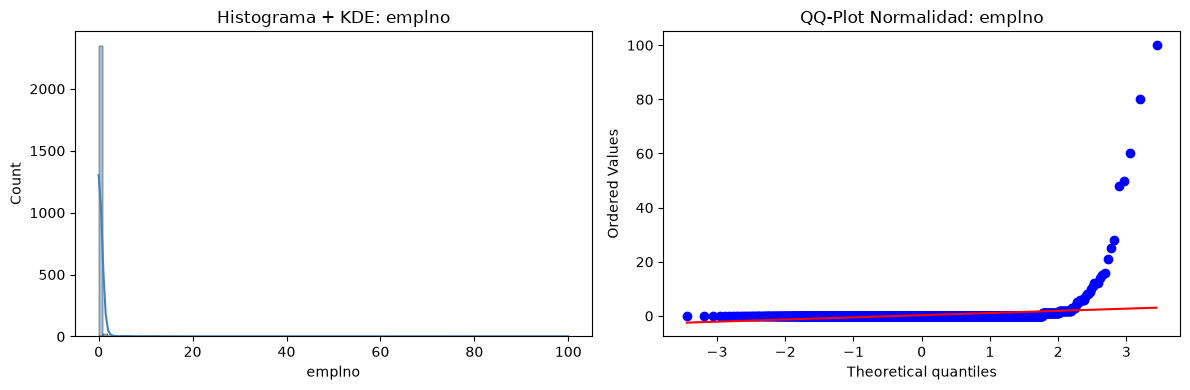

In [4]:
#First of all lets do a quick univariate analysis.
#1)Univariate Data Inspection:

ds3on1(df_71, 'emplno', Desc=True, Stat=True, Graph=True)

🌟 ANÁLISIS 3-EN-1: [AGEA] 🌟

--------------------------------------------------
📖 1. DESCRIPCIÓN
--------------------------------------------------
  Familia estadística : NUMERIC
  Subtipo detectado   : DISCRETE_COUNT
  Detalle             : range 15-999, 77 values

--------------------------------------------------
🧮 2. ESTADÍSTICAS Y DIAGNÓSTICO
--------------------------------------------------

  [numeric/discrete_count]  (n=2400, nulls=0)
  Media: 56.0400 | Mediana: 53.0000
  Q1/Q3: 37.0000 / 66.0000 | IQR: 29.0000
  Min/Max: 15.0000 / 999.0000
  % ceros (masa puntual): 0.00%

--------------------------------------------------
📊 3. VISUALIZACIÓN ADAPTATIVA
--------------------------------------------------


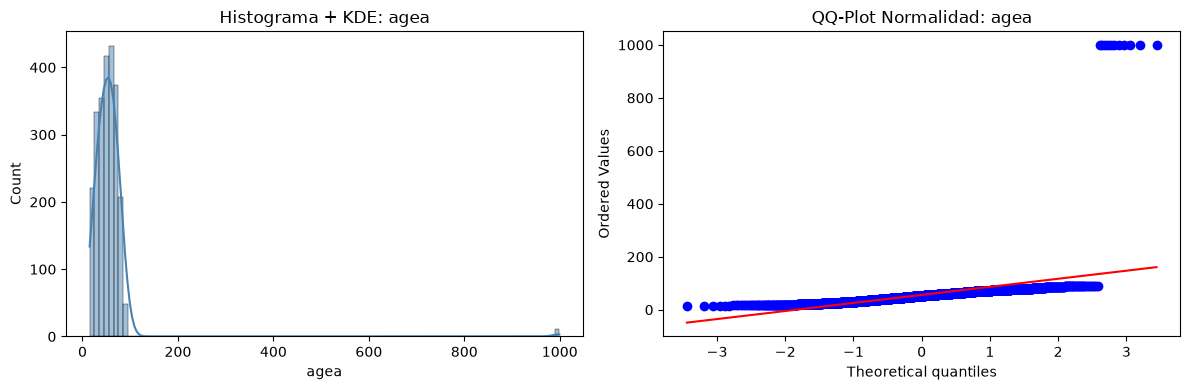

In [5]:
ds3on1(df_71, 'agea', Desc=True, Stat=True, Graph=True)

🌟 ANÁLISIS 3-EN-1: [EMPLREL] 🌟

--------------------------------------------------
📖 1. DESCRIPCIÓN
--------------------------------------------------
  Familia estadística : CATEGORICAL
  Subtipo detectado   : NOMINAL
  Detalle             : 2 categories

--------------------------------------------------
🧮 2. ESTADÍSTICAS Y DIAGNÓSTICO
--------------------------------------------------

  [categorical/nominal]  (n=2400, nulls=0)

  Top Valores:
    1                 2160  ( 90.0%)  ██████████████████████████████
    2                  240  ( 10.0%)  ███
  Únicos: 2
  ⚠️  WARNING: La categoría dominante supera el 50% de los datos.

--------------------------------------------------
📊 3. VISUALIZACIÓN ADAPTATIVA
--------------------------------------------------


/home/josu/Documentos/DataScienceCourse/src/descriptive_tools.py:203: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `y` variable to `hue` and set `legend=False` for the same effect.

  sns.barplot(x=vc.values, y=vc.index.astype(str), ax=axes[0], palette='Blues_r')


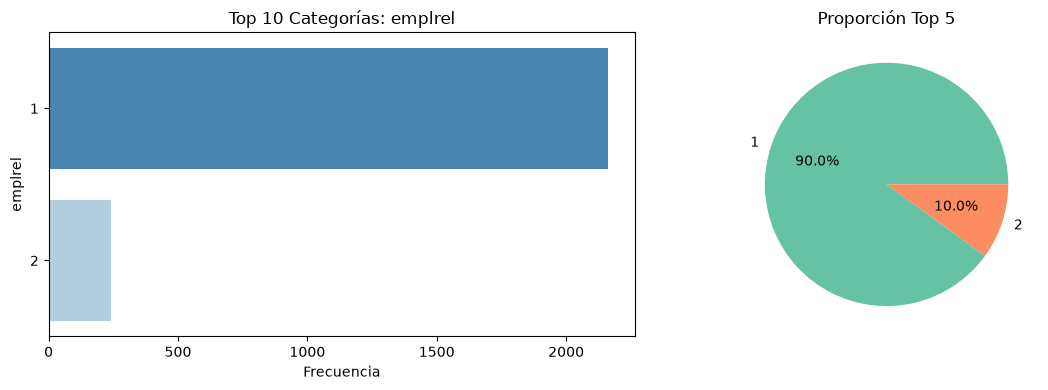

In [6]:
ds3on1(df_71, 'emplrel', Desc=True, Stat=True, Graph=True)

🌟 ANÁLISIS 3-EN-1: [EDULVLB] 🌟

--------------------------------------------------
📖 1. DESCRIPCIÓN
--------------------------------------------------
  Familia estadística : NUMERIC
  Subtipo detectado   : DISCRETE_COUNT
  Detalle             : range 0-9999, 29 values

--------------------------------------------------
🧮 2. ESTADÍSTICAS Y DIAGNÓSTICO
--------------------------------------------------

  [numeric/discrete_count]  (n=2400, nulls=0)
  Media: 464.2371 | Mediana: 322.0000
  Q1/Q3: 313.0000 / 610.0000 | IQR: 297.0000
  Min/Max: 0.0000 / 9999.0000
  % ceros (masa puntual): 0.88%

--------------------------------------------------
📊 3. VISUALIZACIÓN ADAPTATIVA
--------------------------------------------------


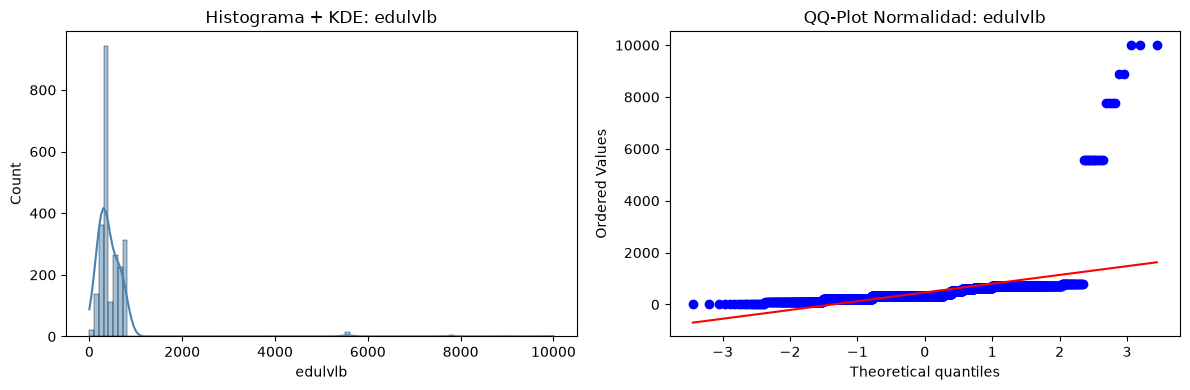

In [7]:
ds3on1(df_71, 'edulvlb', Desc=True, Stat=True, Graph=True)

In [ ]:
-edulvlb: – Education and profesional level of the respondent, ISCED codification . Discrete, non-negative ordinal value (the more qualification, higher code respondent has.).
          - Outliers / sentinel values: 6666, 7777, 8888, 9999 are non-response or data-entry error codes. Also there is a respondent minority class on 0 value, 
"ISCED 0 (early childhood / no formal education): ~1% of respondents"
          - Median observation tell us our frecuency or porportion is located with mayor mass in the Q2-Q3 range. We can observe an non high leptokurtosis and right-skewed distribution.          
          - The 50% of our mass fluctuates from 313(Q1)ISCED code to 610(Q3) code. This mas is located in 297(IQR) codification range.
          - This variable could be transformed in 3 or 4 categorical groups, also be binned in 3 variables in the case we need for the feature engineering.
                                                                                                                               

🌟 ANÁLISIS 3-EN-1: [HAPPY] 🌟

--------------------------------------------------
📖 1. DESCRIPCIÓN
--------------------------------------------------
  Familia estadística : NUMERIC
  Subtipo detectado   : DISCRETE_COUNT
  Detalle             : range 0-99, 14 values

--------------------------------------------------
🧮 2. ESTADÍSTICAS Y DIAGNÓSTICO
--------------------------------------------------

  [numeric/discrete_count]  (n=2400, nulls=0)
  Media: 7.8121 | Mediana: 8.0000
  Q1/Q3: 7.0000 / 9.0000 | IQR: 2.0000
  Min/Max: 0.0000 / 99.0000
  % ceros (masa puntual): 0.46%

--------------------------------------------------
📊 3. VISUALIZACIÓN ADAPTATIVA
--------------------------------------------------


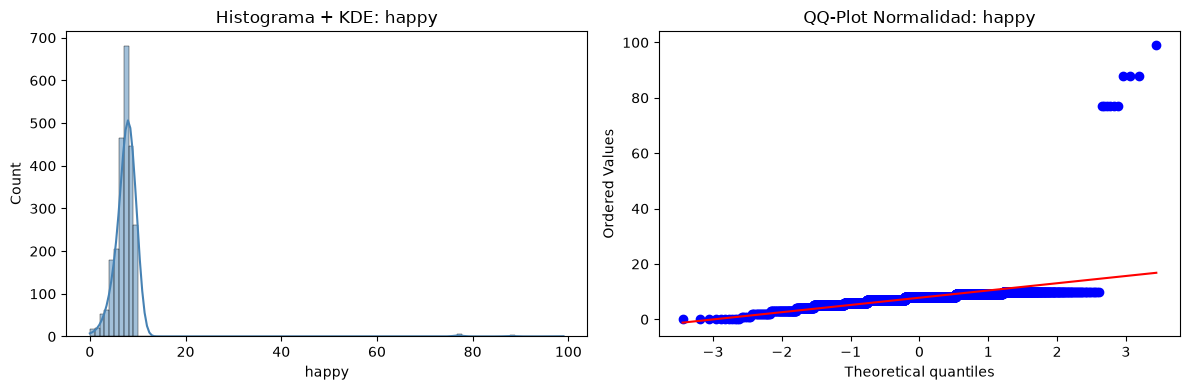

In [9]:
ds3on1(df_71, 'happy', Desc=True, Stat=True, Graph=True)

In [ ]:
-happy: – State of happyness the respondent has, being 0 unhappy and 10 the max value on lickert scale. Discrete, non-negative ordinal value. 15 ordinal unique values
        - Outliers / sentinel values: 66, 77, 88, 99 are non-response or data-entry error codes.
        - The mean (7.8) is slightly below the median (8), consistent with the left skew: the thin tail of low-satisfaction responses (0–5) pulls the mean downward, while the median remains anchored in the central mass at 7–8.
        - The iqr range is so compressed, and the mean-median relation tells us in that 50% of mass respondents, respondents are more close to 8 value of happy than 7.
        - Implication: The limited dynamic range in the central mass makes the raw variable poorly discriminative for modelling.
        Options:
            -Binarize: satisfied = happy ≥ 8 (aligns with Eurostat's own "satisfied / not satisfied" split). Best if the RQ is "what predicts being satisfied?"
            -Categorical (3–4 groups): Unhappy (0–4), Neutral (5–6), Satisfied (7–8), Very satisfied (9–10). Best for ordinal regression (proportional odds).
            -Keep as interval (0–10): Defensible for OLS / random effects if you assume equal spacing. Best if the RQ is "what predicts the level of satisfaction?" and you want to use the full range.
        The choice depends on which RQ it serves. For RQ3 (economic predictors), the interval version preserves more information; for RQ4 (clustering), the categorical version is more robust.

count                                                             2400
categories count                                                    24
Uniques frecuency    cntry
AT    100
BE    100
BG    100
CH    100
...
min                                                                 AT
max                                                                 SK
dtype: object


/tmp/ipykernel_99550/243739368.py:30: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `y` variable to `hue` and set `legend=False` for the same effect.

  sns.barplot(data=counts, x='count', y='cntry', palette='viridis', legend=False)


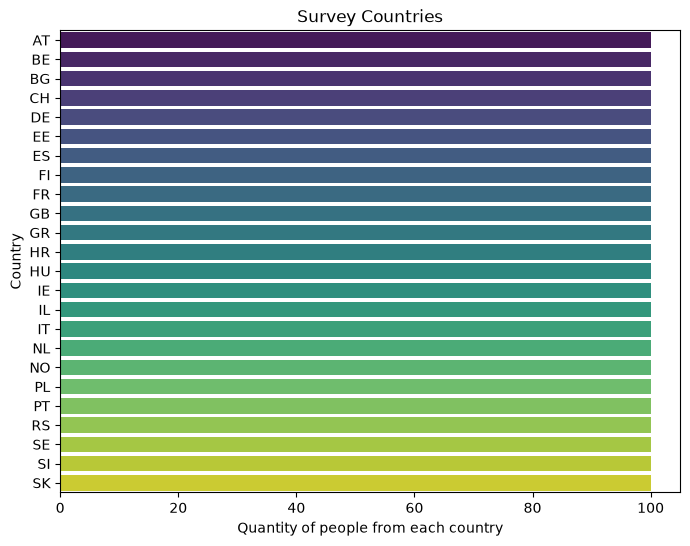

In [11]:

col=df_71['cntry']
def quick_stats(col):
    mode = col.mode()
    return pd.Series({
        'count':  col.count(),
        'categories count': col.nunique(),
        'Uniques frecuency': col.value_counts(),
        #'mean':   col.mean(),
        #'std':    col.std(),
        'min':    col.min(),
        #'Q1':     col.quantile(.25),
        #'median': col.median(),
        #'Q3':     col.quantile(.75),
        'max':    col.max(),
        #'mode':   mode[0] if not mode.empty else np.nan,
        #'skew':   col.skew(),
        #'kurtosis': col.kurt()
    }) 
print(quick_stats(col))
#Being non factorized discrete categorical column, most of our metrics can't be used.
import matplotlib.pyplot as plt
import seaborn as sns
# 1. Sort and calculate frecuencies
counts = df_71['cntry'].value_counts().reset_index()
counts.columns = ['cntry', 'count']

plt.figure(figsize=(8, 6))
# 2. Swap the axis being Y axis the country codes and X the number of rows.
sns.barplot(data=counts, x='count', y='cntry', palette='viridis', legend=False)

plt.title('Survey Countries')
plt.xlabel('Quantity of people from each country')
plt.ylabel('Country')
plt.show()

In [ ]:
-cntry: – the string values (countries) are ordered in order of appearance, 
it is the variable that we have used to create the dataframe using grouping and maximum number of random samples.

🌟 ANÁLISIS 3-EN-1: [LRSCALE] 🌟

--------------------------------------------------
📖 1. DESCRIPCIÓN
--------------------------------------------------
  Familia estadística : NUMERIC
  Subtipo detectado   : DISCRETE_COUNT
  Detalle             : range 0-99, 14 values

--------------------------------------------------
🧮 2. ESTADÍSTICAS Y DIAGNÓSTICO
--------------------------------------------------

  [numeric/discrete_count]  (n=2400, nulls=0)
  Media: 14.2529 | Mediana: 5.0000
  Q1/Q3: 4.0000 / 7.0000 | IQR: 3.0000
  Min/Max: 0.0000 / 99.0000
  % ceros (masa puntual): 3.21%

--------------------------------------------------
📊 3. VISUALIZACIÓN ADAPTATIVA
--------------------------------------------------


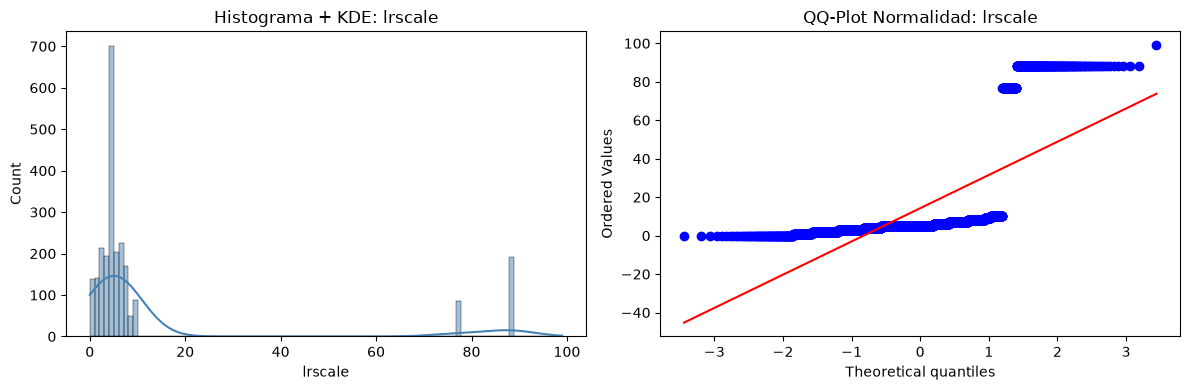

In [13]:
ds3on1(df_71, 'lrscale', Desc=True, Stat=True, Graph=True)

🌟 ANÁLISIS 3-EN-1: [EMPLOYTYPE] 🌟

--------------------------------------------------
📖 1. DESCRIPCIÓN
--------------------------------------------------
  Familia estadística : CATEGORICAL
  Subtipo detectado   : NOMINAL
  Detalle             : 2 categories

--------------------------------------------------
🧮 2. ESTADÍSTICAS Y DIAGNÓSTICO
--------------------------------------------------

  [categorical/nominal]  (n=2400, nulls=0)

  Top Valores:
    1                 2160  ( 90.0%)  ██████████████████████████████
    2                  240  ( 10.0%)  ███
  Únicos: 2
  ⚠️  WARNING: La categoría dominante supera el 50% de los datos.

--------------------------------------------------
📊 3. VISUALIZACIÓN ADAPTATIVA
--------------------------------------------------


/home/josu/Documentos/DataScienceCourse/src/descriptive_tools.py:203: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `y` variable to `hue` and set `legend=False` for the same effect.

  sns.barplot(x=vc.values, y=vc.index.astype(str), ax=axes[0], palette='Blues_r')


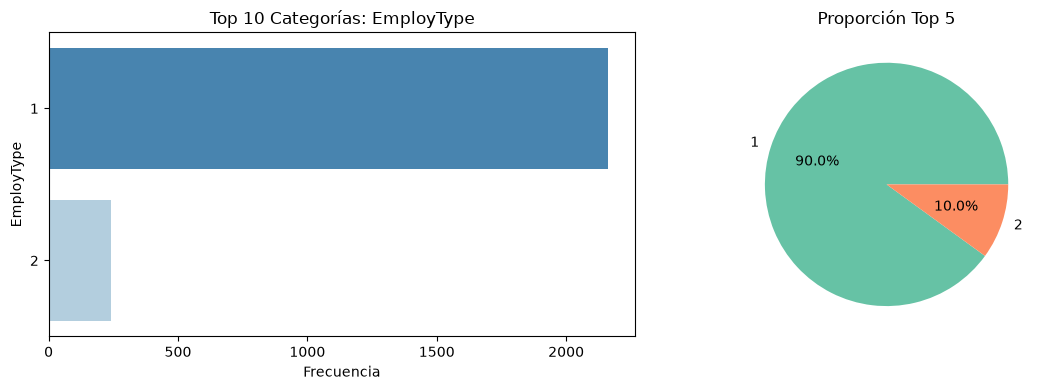

In [14]:
ds3on1(df_71, 'EmployType', Desc=True, Stat=True, Graph=True)

🌟 ANÁLISIS 3-EN-1: [TRSTPRL] 🌟

--------------------------------------------------
📖 1. DESCRIPCIÓN
--------------------------------------------------
  Familia estadística : NUMERIC
  Subtipo detectado   : DISCRETE_COUNT
  Detalle             : range 0-88, 13 values

--------------------------------------------------
🧮 2. ESTADÍSTICAS Y DIAGNÓSTICO
--------------------------------------------------

  [numeric/discrete_count]  (n=2400, nulls=0)
  Media: 5.9496 | Mediana: 5.0000
  Q1/Q3: 3.0000 / 7.0000 | IQR: 4.0000
  Min/Max: 0.0000 / 88.0000
  % ceros (masa puntual): 11.50%

--------------------------------------------------
📊 3. VISUALIZACIÓN ADAPTATIVA
--------------------------------------------------


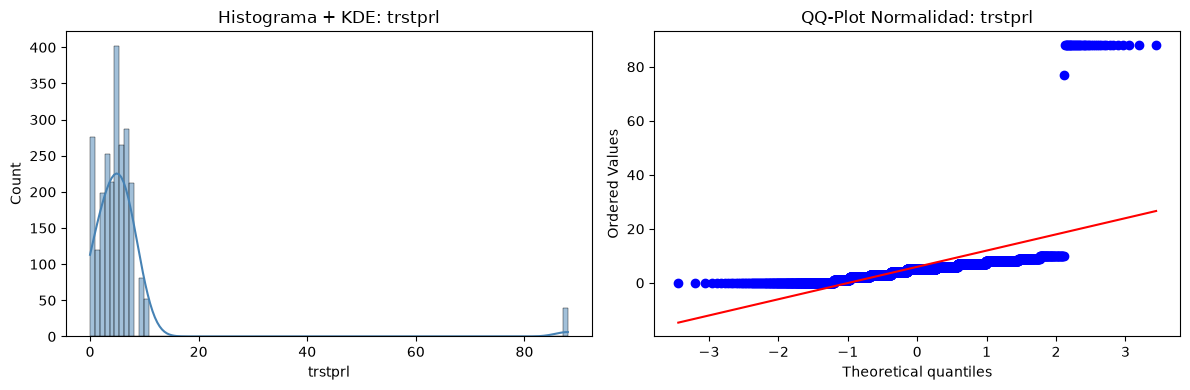

In [15]:
ds3on1(df_71, 'trstprl', Desc=True, Stat=True, Graph=True)

🌟 ANÁLISIS 3-EN-1: [TRSTLGL] 🌟

--------------------------------------------------
📖 1. DESCRIPCIÓN
--------------------------------------------------
  Familia estadística : NUMERIC
  Subtipo detectado   : DISCRETE_COUNT
  Detalle             : range 0-88, 12 values

--------------------------------------------------
🧮 2. ESTADÍSTICAS Y DIAGNÓSTICO
--------------------------------------------------

  [numeric/discrete_count]  (n=2400, nulls=0)
  Media: 6.8279 | Mediana: 6.0000
  Q1/Q3: 4.0000 / 8.0000 | IQR: 4.0000
  Min/Max: 0.0000 / 88.0000
  % ceros (masa puntual): 6.71%

--------------------------------------------------
📊 3. VISUALIZACIÓN ADAPTATIVA
--------------------------------------------------


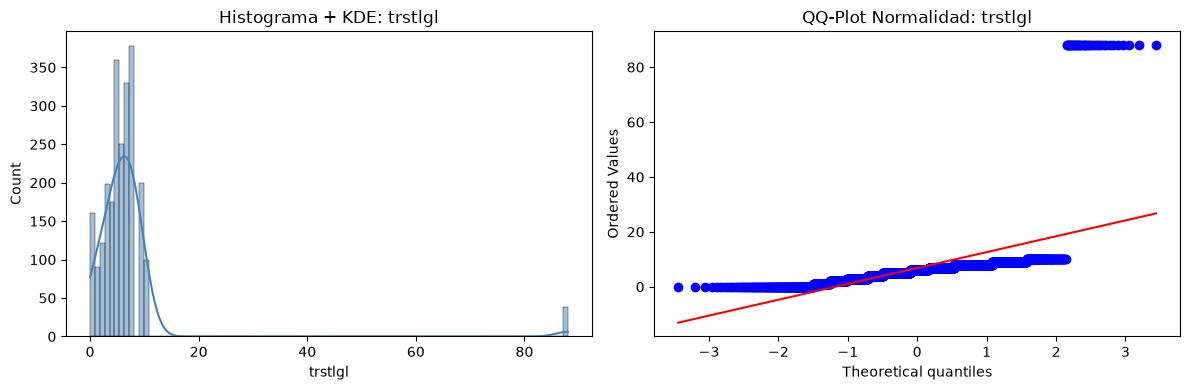

In [16]:
 ds3on1(df_71, 'trstlgl', Desc=True, Stat=True, Graph=True)

In [17]:
# 2.1) Data Preparation.
#A) Value filtering function, this function searches non valid values, starting from mayor numbers, clustered on 4 posible numbers in 4 different lists. Stores this information and then inputs nan on those value cells.
# Also makes a control variable called "n_nonresp" whenever there is an invalid or unanswered value in the row, the n_nonresp counter adds one
def clean_and_count(df):

    df = df.copy()
    df["n_nonresp"] = 0
    report = {}

    # Grupos de mayor a menor cifra
    CODE_GROUPS = [
        [99999, 88888, 77777, 66666],  # 5 dígitos
        [9999,  8888,  7777,  6666],   # 4 dígitos
        [999,   888,   777,   666],    # 3 dígitos
        [99,    88,    77,    66],     # 2 dígitos
    ]

    for col in df.columns:
        if col == "n_nonresp":
            continue

        unique = set(df[col].dropna().unique())

        # Embudo: primero el grupo de mayor cifra
        codes_found = None
        for group in CODE_GROUPS:
            hit = [c for c in group if c in unique]
            if hit:
                codes_found = hit
                break  # se cierra con este grupo, no se mira el siguiente

        if codes_found is None:
            continue  # ningún código presente, se descarta

        # Detección
        mask_invalid = df[col].isin(codes_found)
        n_invalid = int(mask_invalid.sum())

        # Contador
        df.loc[mask_invalid, "n_nonresp"] += 1

        # Setear a NaN
        df.loc[mask_invalid, col] = np.nan

        report[col] = {
            "codes": codes_found,
            "n_invalid": n_invalid,
            "pct_invalid": round(n_invalid / len(df) * 100, 2)
        }

    return df, report   

In [18]:
#A) Appliyng the function:
df_71, report = clean_and_count(df_71)  # ← reasignas   

In [19]:
df_71['n_nonresp'].describe()

count    2400.000000
mean        0.160833
std         0.432100
min         0.000000
25%         0.000000
50%         0.000000
75%         0.000000
max         3.000000
Name: n_nonresp, dtype: float64

In [20]:
#2.1.B) Hot-deck random imputation, we will consider filling NAN values with a weigthed value, attending on original density/distribution of each column.

def hot_deck_impute(df, seed=42):

    rng = np.random.default_rng(seed)
    df = df.copy()
    report = {}

    for col in df.columns:
        if col == "n_nonresp":
            continue

        n_nan = df[col].isna().sum()
        if n_nan == 0:
            continue

        # Distribución empírica de valores válidos
        valid = df[col].dropna()
        weights = valid.value_counts(normalize=True)

        # Muestreo con reemplazo
        imputed = rng.choice(weights.index, size=n_nan, p=weights.values)

        df.loc[df[col].isna(), col] = imputed

        report[col] = {
            "n_imputed": int(n_nan),
            "n_valid_before": int(len(valid)),
            "pct_imputed": round(n_nan / len(df) * 100, 2)
        }

    return df, report 

In [21]:
df_71, imp_report = hot_deck_impute(df_71, seed=42)
print(imp_report)
 

{'agea': {'n_imputed': 11, 'n_valid_before': 2389, 'pct_imputed': np.float64(0.46)}, 'edulvlb': {'n_imputed': 9, 'n_valid_before': 2391, 'pct_imputed': np.float64(0.38)}, 'happy': {'n_imputed': 10, 'n_valid_before': 2390, 'pct_imputed': np.float64(0.42)}, 'lrscale': {'n_imputed': 277, 'n_valid_before': 2123, 'pct_imputed': np.float64(11.54)}, 'trstprl': {'n_imputed': 41, 'n_valid_before': 2359, 'pct_imputed': np.float64(1.71)}, 'trstlgl': {'n_imputed': 38, 'n_valid_before': 2362, 'pct_imputed': np.float64(1.58)}}


In [22]:
df_71.info()

<class 'pandas.DataFrame'>
RangeIndex: 2400 entries, 0 to 2399
Data columns (total 11 columns):
 #   Column      Non-Null Count  Dtype  
---  ------      --------------  -----  
 0   emplno      2400 non-null   int64  
 1   agea        2400 non-null   float64
 2   emplrel     2400 non-null   int64  
 3   edulvlb     2400 non-null   float64
 4   happy       2400 non-null   float64
 5   lrscale     2400 non-null   float64
 6   cntry       2400 non-null   str    
 7   EmployType  2400 non-null   int32  
 8   trstprl     2400 non-null   float64
 9   trstlgl     2400 non-null   float64
 10  n_nonresp   2400 non-null   int64  
dtypes: float64(6), int32(1), int64(3), str(1)
memory usage: 202.0 KB


In [23]:
#Before multivariate visualization and clustering.
#Lets transform all ordinals in to int again.
def cast_to_int(df, cols):
    
    df = df.copy()
    for col in cols:
        df[col] = df[col].astype(int)
    return df 


In [24]:
df_71 = cast_to_int(df_71, ["agea", "edulvlb", "happy", "lrscale", "trstprl", "trstlgl"])
df_71.info()

<class 'pandas.DataFrame'>
RangeIndex: 2400 entries, 0 to 2399
Data columns (total 11 columns):
 #   Column      Non-Null Count  Dtype
---  ------      --------------  -----
 0   emplno      2400 non-null   int64
 1   agea        2400 non-null   int64
 2   emplrel     2400 non-null   int64
 3   edulvlb     2400 non-null   int64
 4   happy       2400 non-null   int64
 5   lrscale     2400 non-null   int64
 6   cntry       2400 non-null   str  
 7   EmployType  2400 non-null   int32
 8   trstprl     2400 non-null   int64
 9   trstlgl     2400 non-null   int64
 10  n_nonresp   2400 non-null   int64
dtypes: int32(1), int64(9), str(1)
memory usage: 202.0 KB


In [25]:
#Grouping by logic clusters (economic, macro region, n_nonresp value and non clustered)
#Lets use our Europe information table created in the branch "git checkout Datacollect1", with macro region information and eurostat-wordlbank data.

con.execute(attach_query)
df_Eu = con.execute("SELECT * FROM db.macro_panel").df()
df_Eu.info()





<class 'pandas.DataFrame'>
RangeIndex: 45 entries, 0 to 44
Data columns (total 8 columns):
 #   Column                Non-Null Count  Dtype  
---  ------                --------------  -----  
 0   geo                   45 non-null     str    
 1   year                  45 non-null     int64  
 2   macro_region          45 non-null     str    
 3   gdpcapitapct          45 non-null     float64
 4   ginicoefpct           45 non-null     float64
 5   inflationpct          45 non-null     float64
 6   reglangdemographypct  45 non-null     float64
 7   unemploymentpct       45 non-null     float64
dtypes: float64(5), int64(1), str(2)
memory usage: 3.4 KB


In [26]:
#Lets get only the values for the 2024 year.
df_macro_2024 = df_Eu[df_Eu["year"] == 2024].copy()
print(df_macro_2024.shape)  # debería ser (15, 8)   

(15, 8)


In [27]:
print(df_Eu["year"].unique())  # Registered years data
print(df_macro_2024.shape)     # how many columns
print(df_macro_2024.columns.tolist())  # ¿the name of columns

[2004 2014 2024]
(15, 8)
['geo', 'year', 'macro_region', 'gdpcapitapct', 'ginicoefpct', 'inflationpct', 'reglangdemographypct', 'unemploymentpct']


In [28]:
#Our Economic information is limited due the lack of information of some of newest Eu regions,
# We will delete from our df_71 those countries without economic data, because we want to see
# how our data distribution is affected when grouping or non grouping.
# Countries with data information.
valid_countries = set(df_macro_2024["geo"].unique())
macro_cols = ['macro_region','gdpcapitapct','ginicoefpct','inflationpct', 'reglangdemographypct','unemploymentpct']
                                                                                                 
# filter df_71
df_71_clean = df_71[df_71["cntry"].isin(valid_countries)].copy()
print(f"Filas antes: {len(df_71)} → después: {len(df_71_clean)}")
print(f"Países: {df_71_clean['cntry'].nunique()}")

# Clean merge
df_71_clean = df_71_clean.merge(
    df_macro_2024[["geo"] + macro_cols],
    left_on="cntry", right_on="geo", how="left"
)
print(df_71_clean["gdpcapitapct"].isna().sum())  # 0   

Filas antes: 2400 → después: 1500
Países: 15
0


In [29]:
df_71.info()

<class 'pandas.DataFrame'>
RangeIndex: 2400 entries, 0 to 2399
Data columns (total 11 columns):
 #   Column      Non-Null Count  Dtype
---  ------      --------------  -----
 0   emplno      2400 non-null   int64
 1   agea        2400 non-null   int64
 2   emplrel     2400 non-null   int64
 3   edulvlb     2400 non-null   int64
 4   happy       2400 non-null   int64
 5   lrscale     2400 non-null   int64
 6   cntry       2400 non-null   str  
 7   EmployType  2400 non-null   int32
 8   trstprl     2400 non-null   int64
 9   trstlgl     2400 non-null   int64
 10  n_nonresp   2400 non-null   int64
dtypes: int32(1), int64(9), str(1)
memory usage: 202.0 KB


In [30]:
del df_71, df_macro_2024, df_Eu

In [36]:
from sklearn.cluster import KMeans
from sklearn.preprocessing import StandardScaler   
def kmeans_economic(df, macro_num_cols, n_clusters=3, seed=42):

    macro_df = df[["cntry", "macro_region"] + macro_num_cols].drop_duplicates(subset="cntry").reset_index(drop=True)

    neg_vars = ['ginicoefpct', 'inflationpct', 'unemploymentpct']
    pos_vars = [c for c in macro_num_cols if c not in neg_vars]

    for col in neg_vars:
        macro_df[f"{col}_inv"] = macro_df[col].max() - macro_df[col]

    cluster_cols = pos_vars + [f"{c}_inv" for c in neg_vars]

    X = macro_df[cluster_cols].values
    X_scaled = StandardScaler().fit_transform(X)

    kmeans = KMeans(n_clusters=n_clusters, random_state=seed, n_init=10)
    macro_df["econ_cluster"] = kmeans.fit_predict(X_scaled)

    # Etiquetar por GDP medio: 0=bajo, 1=medio, 2=alto
    gdp_by_cluster = macro_df.groupby("econ_cluster")["gdpcapitapct"].mean().sort_values()
    label_map = {old: new for new, old in enumerate(gdp_by_cluster.index)}
    macro_df["econ_cluster"] = macro_df["econ_cluster"].map(label_map)

    df = df.merge(macro_df[["cntry", "econ_cluster"]], on="cntry", how="left")

    return df, macro_df   

In [37]:
macro_num_cols = ['gdpcapitapct', 'ginicoefpct', 'inflationpct', 'unemploymentpct']
df_71_clean, macro_detail = kmeans_economic(df_71_clean, macro_num_cols, n_clusters=3)   
print(macro_detail[["cntry", "gdpcapitapct", "unemploymentpct", "econ_cluster"]].to_string())   

   cntry   gdpcapitapct  unemploymentpct  econ_cluster
0     AT   58268.878765            5.200             2
1     BE   56581.937564            5.700             2
2     DE   56103.732318            3.400             2
3     EE   31428.354782            7.600             1
4     ES   35326.768307           11.400             1
5     FI   53155.545117            8.400             2
6     FR   46103.084086            7.400             1
7     GB   53341.313109            4.361             1
8     HU   23305.448251            4.500             0
9     IE  112894.953241            4.300             2
10    NL   67465.320813            3.700             2
11    NO   89888.953520            4.000             2
12    PL   25103.565661            2.807             0
13    PT   29328.306742            6.500             1
14    SE   57222.710057            8.400             2


In [38]:
# The clustering reveals that GDP alone does not determine economic profile. Great Britain, despite a GDP comparable to Austria and a similar unemployment rate, is assigned to a lower cluster due to its Gini coefficient (35.1) 
# being the highest in the sample. This suggests the algorithm captures not just income generation but distributional quality as a differentiating axis."

# 3) Multivariate analysis (we will use cntry, macro_region, econ_cluster and n_nonresp to see how this groups alters distribution and shape from our variables)
#Lets define cluster cols for group the data when we compare the other kind of variables/columns.
#We will use general data(all countries), especific countries, in my case cntry==ES, and the rest of group cols.
df_71_clean['is_ES'] = (df_71_clean['cntry'] == 'ES').astype(int)
group_cols = ['is_ES', 'macro_region', 'econ_cluster', 'n_nonresp']
#Lets define the observational cols that will be grouped and compared each other.
study_cols= ['emplno','agea','emplrel','edulvlb','happy','lrscale','EmployType','trstprl','trstlgl']


In [39]:
#Lets use a plot function for all our variables, all our categorical columns for inside of study_cols group are already factorized.
#And compare the distribution within different group_cols
def multivariate_plot(df, study_col, group_cols):
    """
    Para una study_col, itera sobre cada group_col.
    Cada group_col genera una figura de 2 filas:
      Fila 0: bar plot (conteo de frecuencias de study_col por grupo)
      Fila 1: violin + box inner (distribución de study_col por grupo)
    Columnas = valores únicos de la group_col.
    """
    for group_col in group_cols:
        groups = sorted(df[group_col].dropna().unique())
        n_groups = len(groups)

        fig, axes = plt.subplots(2, n_groups, figsize=(3 * n_groups, 7))
        if n_groups == 1:
            axes = axes[:, np.newaxis]  # asegurar 2D

        for j, g in enumerate(groups):
            subset = df[df[group_col] == g][study_col].dropna()

            # --- Fila 0: Bar plot ---
            ax_bar = axes[0, j]
            counts = subset.value_counts().sort_index()
            ax_bar.bar(counts.index.astype(str), counts.values, color='steelblue', edgecolor='white')
            ax_bar.set_title(f"{study_col} | {group_col}={g}\n(n={len(subset)})", fontsize=8)
            ax_bar.set_xlabel("")
            ax_bar.set_ylabel("Frecuencia")

            # --- Fila 1: Violin + box inner ---
            ax_violin = axes[1, j]
            sns.violinplot(y=subset, ax=ax_violin, inner='box',
                           color='steelblue', cut=0, bw_adjust=0.7)
            ax_violin.set_title(f"{study_col} | {group_col}={g}\n(n={len(subset)})", fontsize=8)
            ax_violin.set_xlabel("")
            ax_violin.set_ylabel("")

        plt.suptitle(f"{study_col} × {group_col}", fontsize=12, y=1.02)
        plt.tight_layout()
        plt.show()   

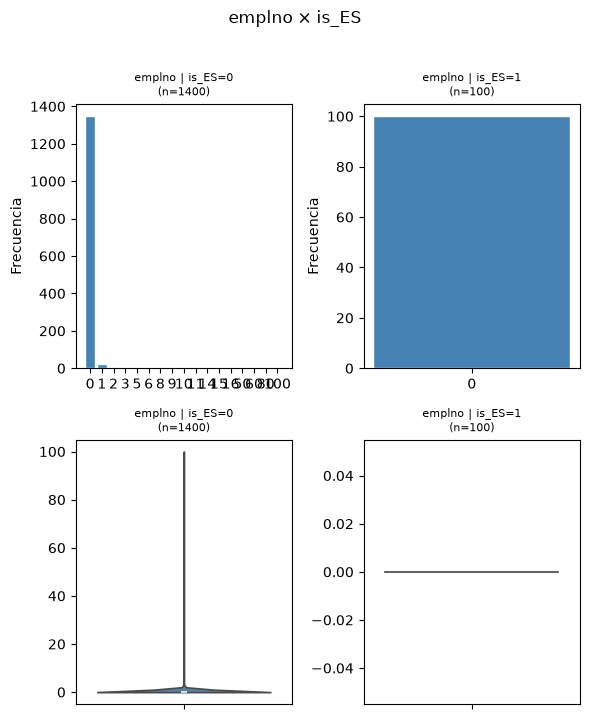

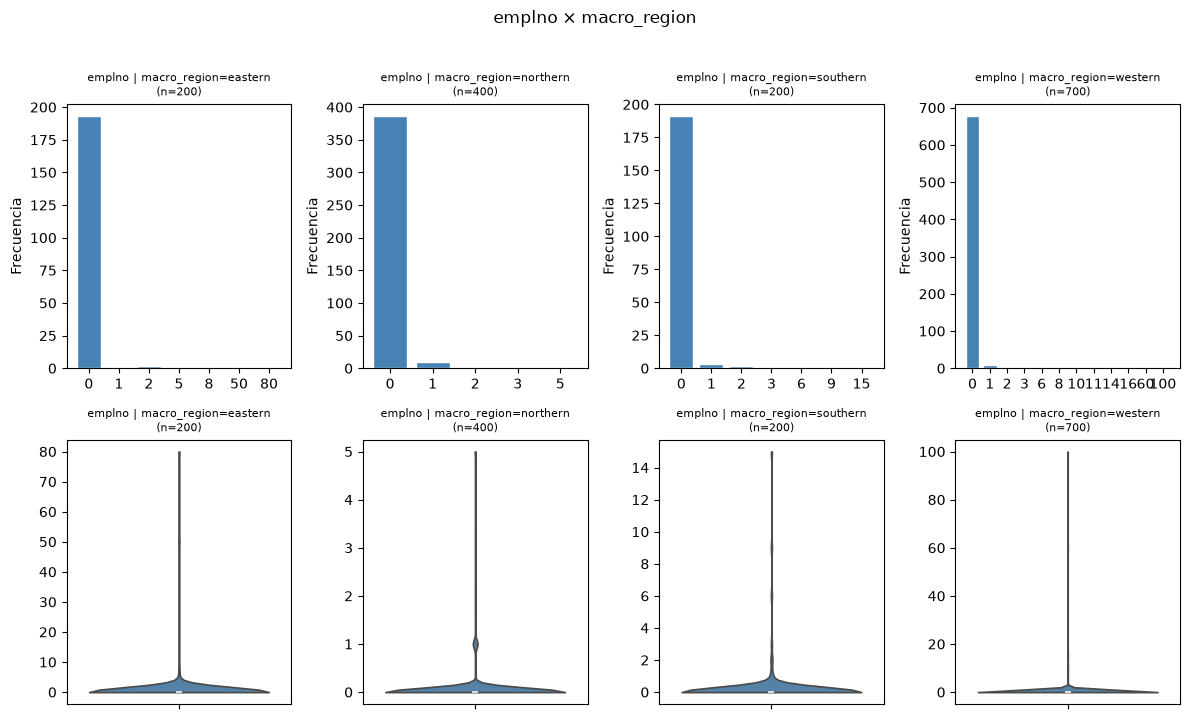

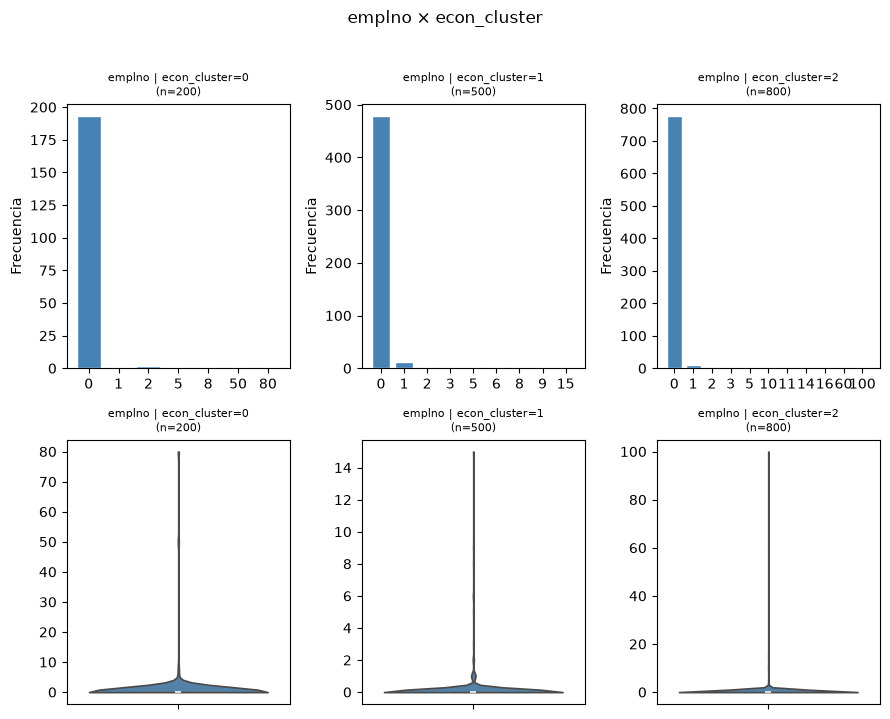

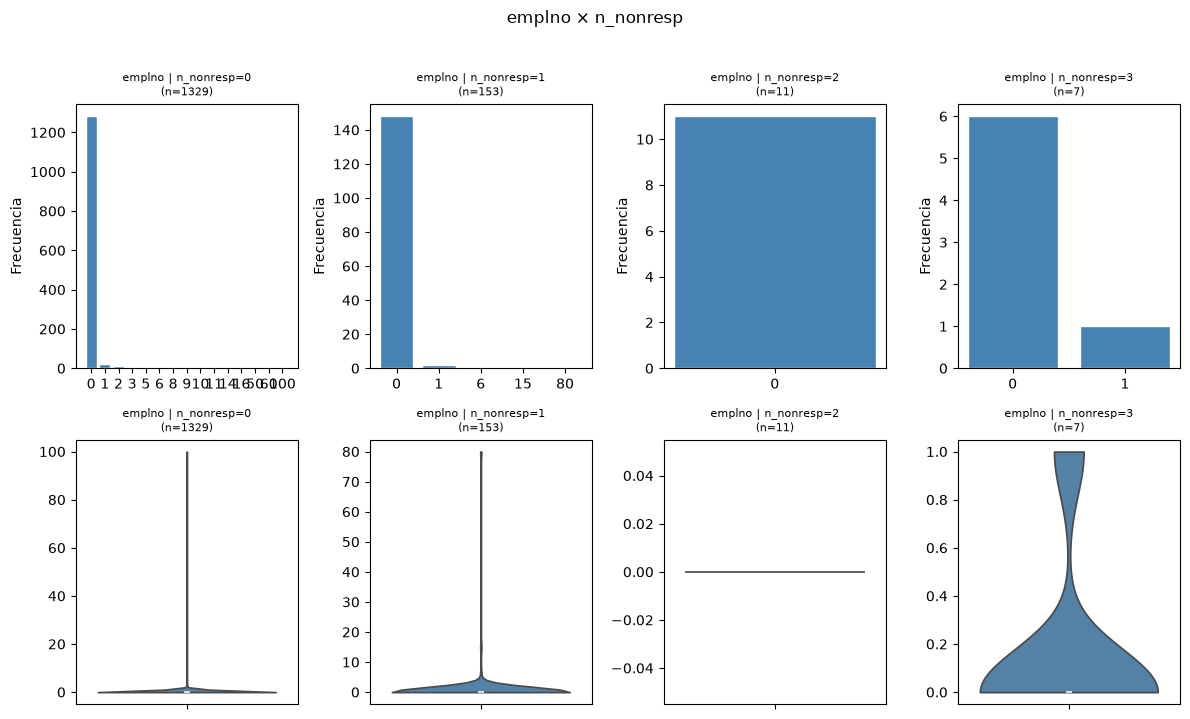

In [40]:
multivariate_plot(df_71_clean, 'emplno', group_cols)   

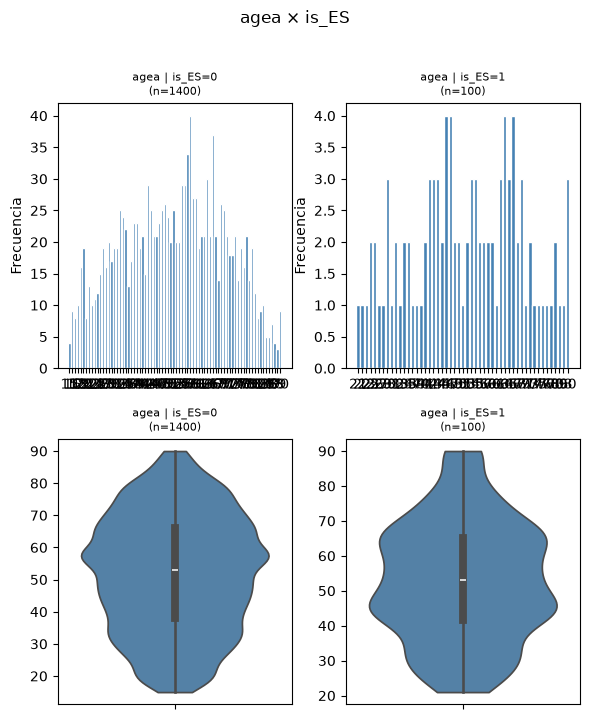

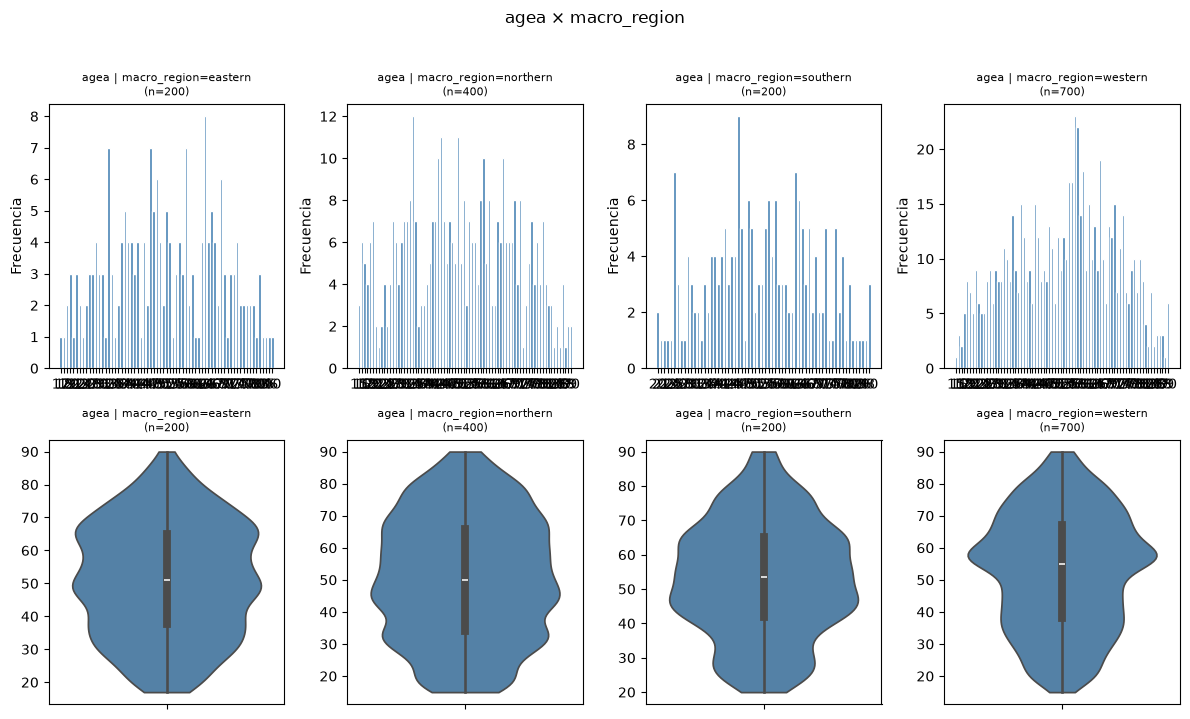

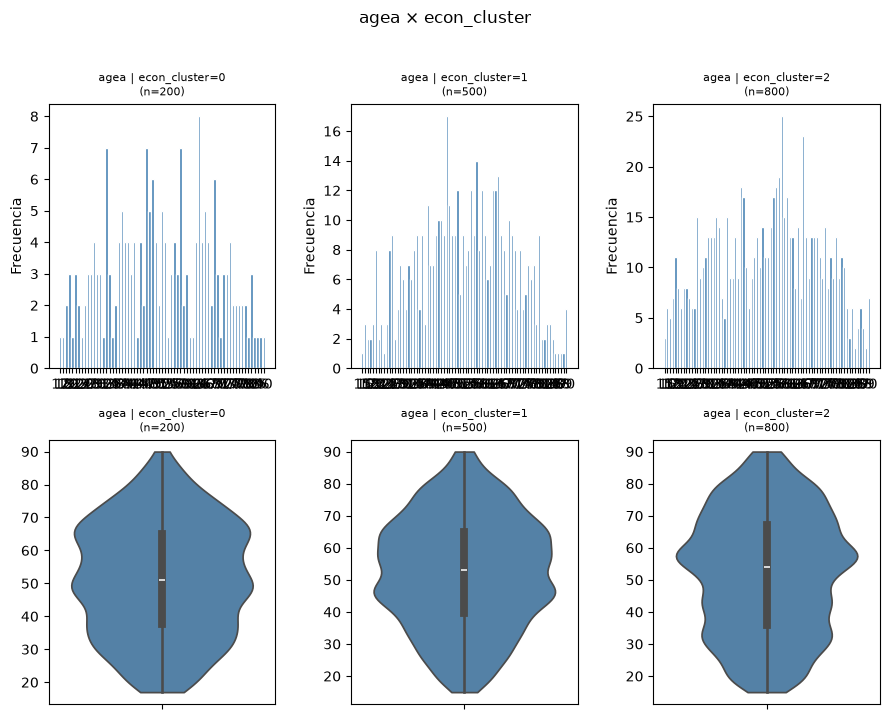

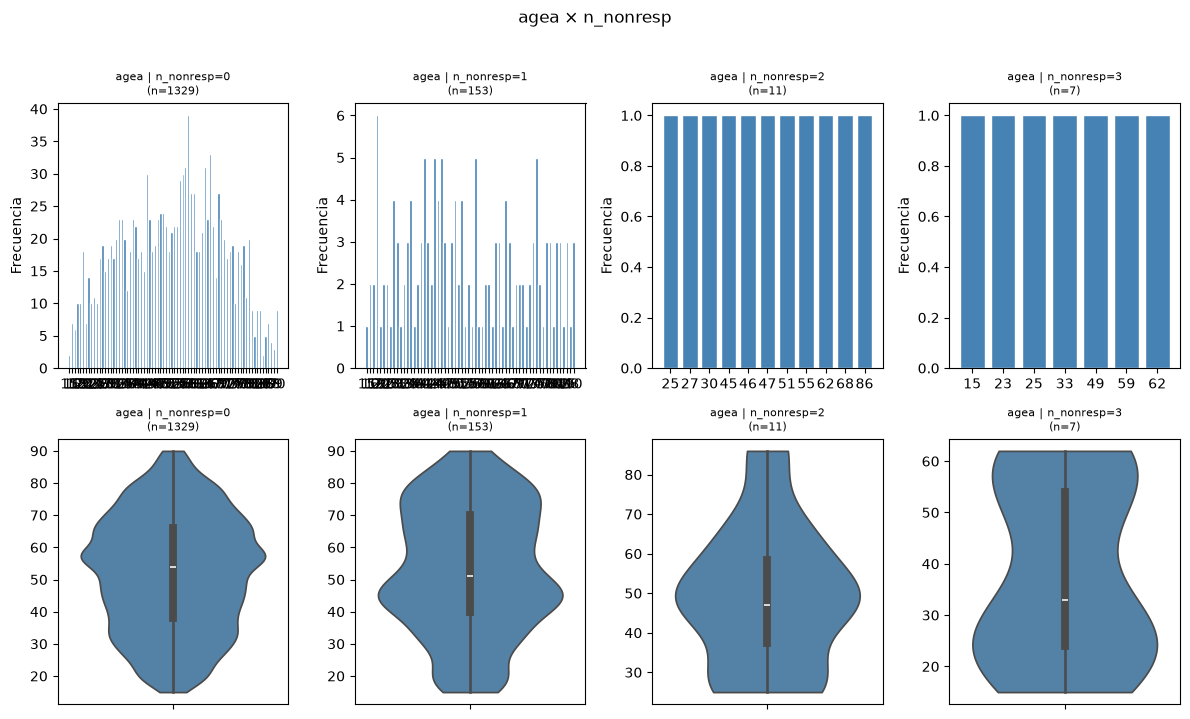

In [41]:
multivariate_plot(df_71_clean, 'agea', group_cols)  

In [42]:
'agea' - In the first group comparison (Spanish or not) we can observe how the distribution changes from unimodal shape
around 60 years old to bimodality with low kurtosis(the density is well spread) exactly in the age of 35 and 66 years old.
        - The second observation group (macro regions) we can observe different density nodes between the groups, easter has 3 density
nodes on 35, 50 and 65 years old having a good wide representation. Norther is the most balanced between these subgroups. Having a
bit more density on 35 and 45 years old. Southern describes a low kurtosis on 48 years old age, meanwhile western does it around 58 years
old.
We just have 100 samples for each country, so is too quick to evaluate the whole dataset.
        - The third group, economy clusters, the poor ones follows similar graph than eastern macro region, the normal economy countries
has a good representation, having a bit more density on 48 years old, meanwhile rich countries(econ_cluster==2) their density node is around
58 years old, at the same time, its IQR is the most wide between the economic subgroups.
        -In the non response observation subgroups we can observe, that on people with 0 responses its age has a density node on 58 years
old, with an iqr a bit concentrated than non respone =1 having the median higher than the subgroup 2 wich has a bimodality or 2 high
density nodes on 75 years old and 45 years old. Anyways i think hasnt to much correlation because the ages of non respondent doesnt 
have any pattern , it changes totaly when n_nonresp increases.

SyntaxError: invalid syntax (3295988783.py, line 1)

In [43]:
Lets study directly lrscale, due its high relation with non respone values.

SyntaxError: invalid syntax (1946057204.py, line 1)

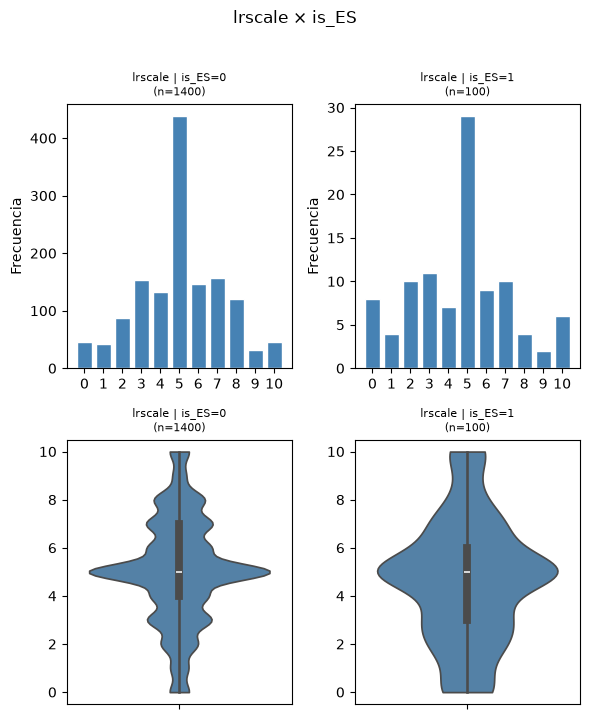

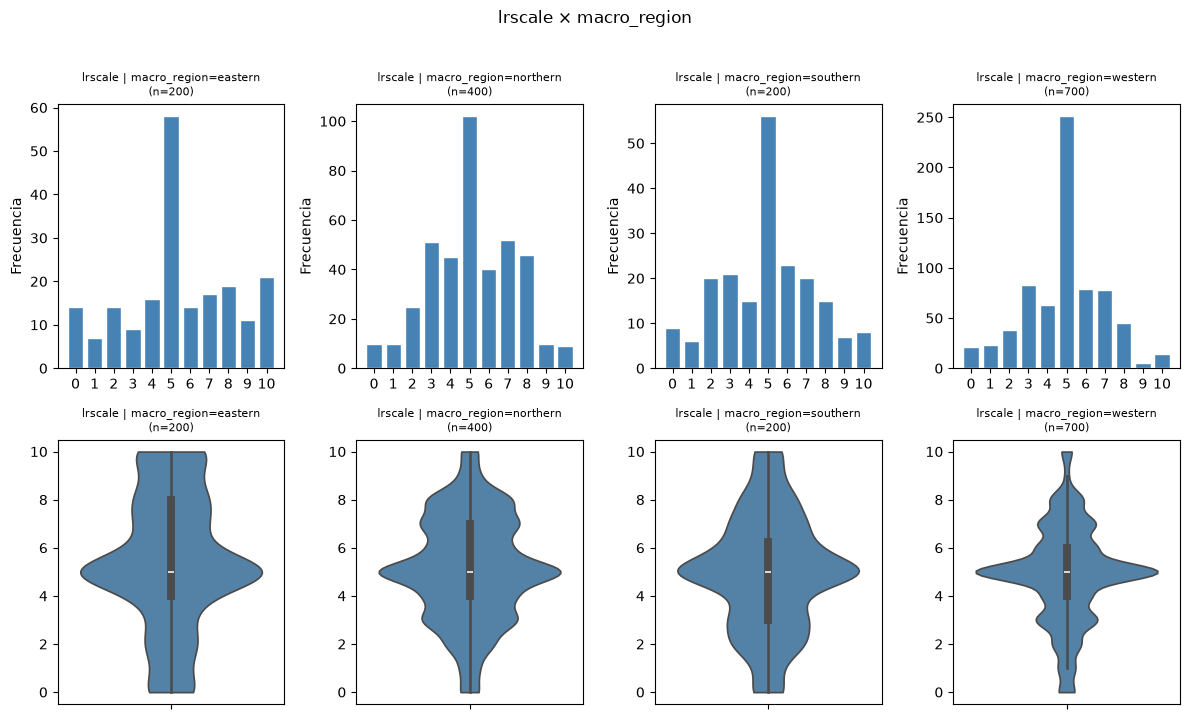

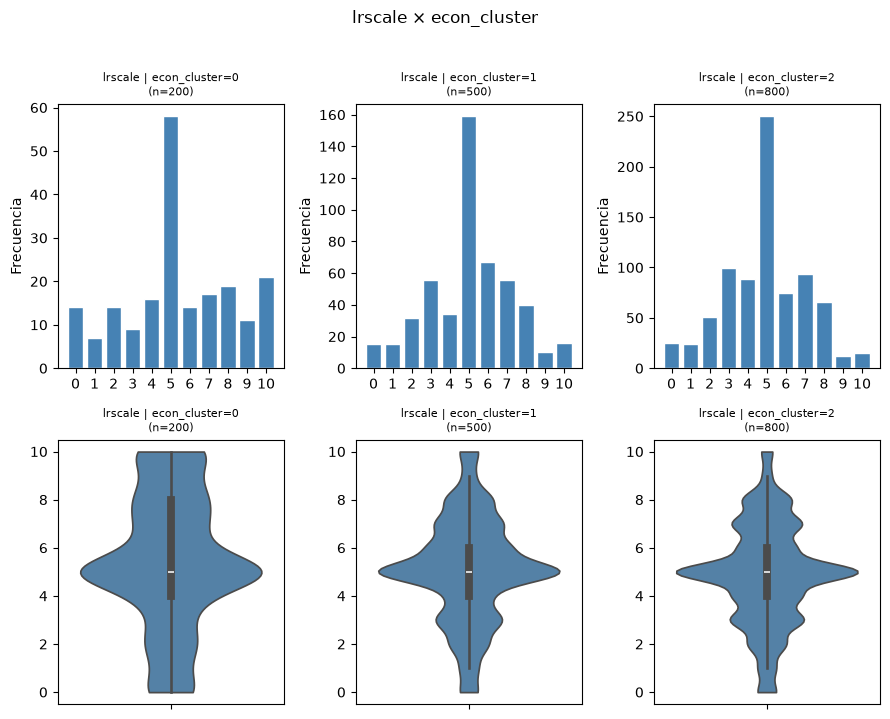

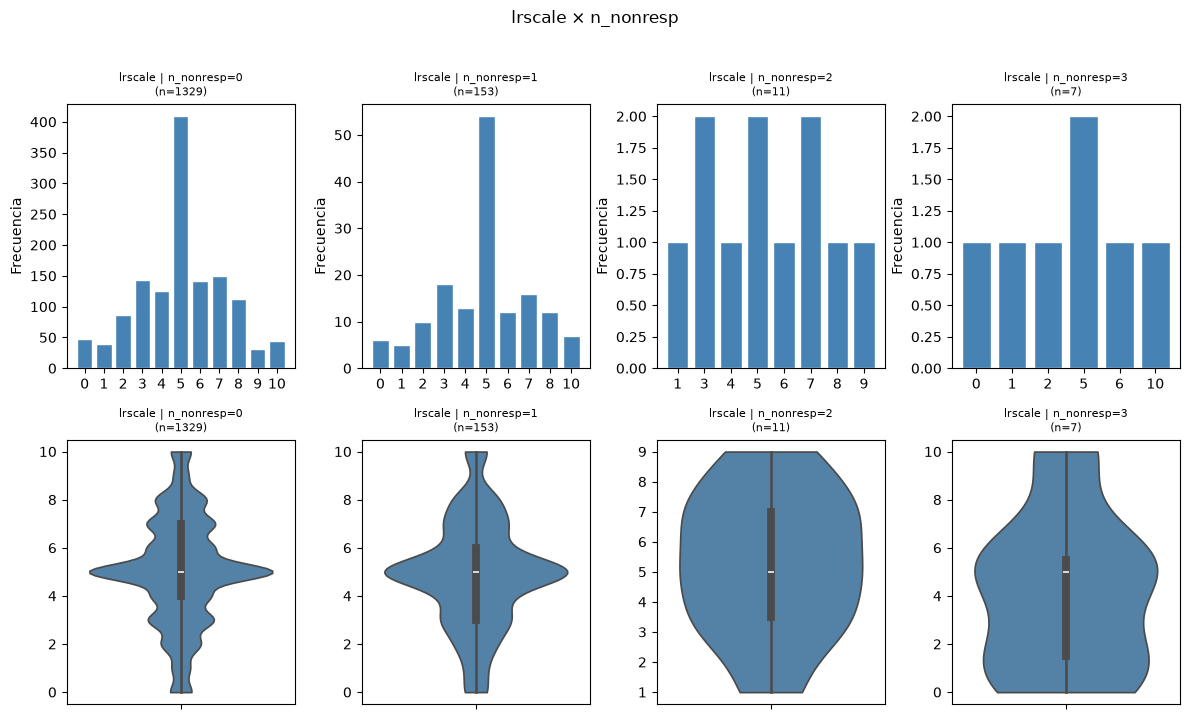

In [44]:
multivariate_plot(df_71_clean, 'lrscale', group_cols)

In [70]:
# One-hot there is no natural order between them.
region_dummies = pd.get_dummies(df_71_clean['macro_region'], prefix='region')
df_71_clean = pd.concat([df_71_clean.drop(columns=region_dummies.columns, errors='ignore'), region_dummies], axis=1)     
# → region_eastern, region_northern, region_southern, region_western   
#We can one-hot econ cluster also, but it has already natural order being 0 poor and 2 rich, it can be usefull for the feature engineering.

# Correlaction dataframe
corr_cols = ['agea', 'happy', 'lrscale', 'trstprl', 'trstlgl',
             'gdpcapitapct', 'ginicoefpct', 'inflationpct',
             'unemploymentpct', 'n_nonresp', 'econ_cluster','region_eastern','region_northern', 'region_southern','region_western'] 

corr = df_71_clean[corr_cols].corr(method='spearman')

In [75]:
corr.style.background_gradient(cmap='RdBu_r', vmin=-1, vmax=1).format('{:.3f}').set_properties(**{'text-align': 'center', 'font-size': '11px'})

,agea,happy,lrscale,trstprl,trstlgl,gdpcapitapct,ginicoefpct,inflationpct,unemploymentpct,n_nonresp,econ_cluster,region_eastern,region_northern,region_southern,region_western
agea,1.000,0.035,0.059,-0.050,-0.024,0.008,0.050,-0.033,0.026,-0.002,0.014,-0.020,-0.044,0.014,0.043
happy,0.035,1.000,0.091,0.181,0.209,0.097,-0.088,-0.012,-0.004,-0.055,0.105,-0.048,0.054,-0.048,0.017
lrscale,0.059,0.091,1.000,0.058,0.033,-0.083,-0.015,-0.005,0.031,-0.023,-0.071,0.058,0.027,-0.012,-0.054
trstprl,-0.050,0.181,0.058,1.000,0.628,0.190,-0.259,-0.113,0.038,-0.131,0.242,-0.106,0.268,-0.136,-0.073
trstlgl,-0.024,0.209,0.033,0.628,1.000,0.226,-0.180,-0.067,0.025,-0.078,0.281,-0.179,0.266,-0.175,0.006
gdpcapitapct,0.008,0.097,-0.083,0.190,0.226,1.000,-0.349,-0.257,-0.239,-0.089,0.876,-0.590,0.140,-0.363,0.526
ginicoefpct,0.050,-0.088,-0.015,-0.259,-0.180,-0.349,1.000,-0.005,0.128,0.148,-0.525,-0.136,-0.419,0.500,0.124
inflationpct,-0.033,-0.012,-0.005,-0.113,-0.067,-0.257,-0.005,1.000,-0.397,-0.004,-0.438,0.590,-0.035,-0.227,-0.217
unemploymentpct,0.026,-0.004,0.031,0.038,0.025,-0.239,0.128,-0.397,1.000,0.017,-0.044,-0.363,0.384,0.409,-0.371
n_nonresp,-0.002,-0.055,-0.023,-0.131,-0.078,-0.089,0.148,-0.004,0.017,1.000,-0.112,0.012,-0.075,0.088,-0.003
